<a href="https://colab.research.google.com/github/ust-buan-640/buan-640-notebooks/blob/main/notebooks/m11-4-reading-output.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Reading the regression output

In the previous notebook we fit the least squares line for all 89 North Ames homes and printed several outputs. Here we go through those outputs one at a time and read what they say about home prices.

*Data: Ames housing data (De Cock, 2011, Journal of Statistics Education), single-family homes in the North Ames neighborhood sold under normal conditions in 2007. `area` is the above-ground living area in square feet, and `price` is the sale price in dollars.*

The same three steps as before: libraries, data, model.

In [3]:
# @title
import pandas as pd
import statsmodels.api as sm

homes = pd.read_csv("https://raw.githubusercontent.com/ust-buan-640/buan-640-notebooks/main/data/north_ames_2007.csv")
model = sm.formula.ols("price ~ area", data=homes).fit()

In [10]:
# @title Setup for the illustrations (colors and helper functions)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import FancyBboxPatch

PURPLE, GOLD, GRAY, LIGHT, SAND = "#510C76", "#B07A00", "#6E6E6E", "#C9B8D6", "#EFE3C2"
plt.rcParams.update({"font.size": 14, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#444444", "axes.labelcolor": "#222222",
                     "xtick.color": "#444444", "ytick.color": "#444444",
                     "axes.titlesize": 14, "legend.fontsize": 12})
DOLLARS = mtick.FuncFormatter(lambda v, p: "$0" if v == 0 else ("−" if v < 0 else "") + f"${abs(v)/1000:,.0f}K")


def fit(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    b1 = np.sum((x - x.mean()) * (y - y.mean())) / np.sum((x - x.mean()) ** 2)
    return y.mean() - b1 * x.mean(), b1


def home_axes(ax, xlim=(700, 2400), ylim=(0, 290000)):
    ax.set_xlim(*xlim); ax.set_ylim(*ylim)
    ax.yaxis.set_major_formatter(DOLLARS)
    ax.set_xlabel("living area (sq ft)"); ax.set_ylabel("sale price")


na = pd.read_csv("https://raw.githubusercontent.com/ust-buan-640/buan-640-notebooks/main/data/north_ames_2007.csv")
x, y = na.area.values.astype(float), na.price.values.astype(float)
b0, b1 = fit(x, y)
yhat = b0 + b1 * x
res = y - yhat
XS = np.linspace(700, 2400, 100)


def box(ax, cx, cy, w, h, text, ec=PURPLE, fc="white", fs=13):
    ax.add_patch(FancyBboxPatch((cx - w / 2, cy - h / 2), w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                                fc=fc, ec=ec, lw=1.6))
    ax.text(cx, cy, text, ha="center", va="center", fontsize=fs)

def arrow(ax, p, q, color=PURPLE):
    ax.annotate("", xy=q, xytext=p, arrowprops=dict(arrowstyle="-|>", color=color, lw=1.6))

plt.rcParams["figure.dpi"] = 110

## The output at a glance

`summary()` packs most of what a regression produces into one table. In this notebook we read the parts that describe the line and how well it fits. The rest belongs to inference, which comes next.

In [ ]:
# @title
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  price   R-squared:                       0.591
Model:                            OLS   Adj. R-squared:                  0.587
Method:                 Least Squares   F-statistic:                     126.0
Date:                Fri, 27 Nov 2026   Prob (F-statistic):           1.35e-18
Time:                        21:12:07   Log-Likelihood:                -997.02
No. Observations:                  89   AIC:                             1998.
Df Residuals:                      87   BIC:                             2003.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   6.536e+04   7223.617      9.049      0.000     5.1e+04    7.97e+04
area          63.9449      5.698     11.223      0.000      52.620      75.270
==============================================================================
Omnibus:                        5.668   Durbin-Watson:                   1.550
Prob(Omnibus):                  0.059   Jarque-Bera (JB):                8.532
Skew:                          -0.085   Prob(JB):                       0.0140
Kurtosis:                       4.507   Cond. No.                     4.82e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 4.82e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

| In the output | What it is | Also available as | Where we read it |
|---|---|---|---|
| `coef` for `Intercept` and `area` | $b_0$ and $b_1$ | `model.params` | this notebook |
| `R-squared` | share of the variation in price explained by the line | `model.rsquared` | this notebook |
| `No. Observations` | $n$, the number of homes | `model.nobs` | this notebook |
| `Df Residuals` | $n - 2$, used in $s_e$ | `model.df_resid` | this notebook |
| `std err`, `t`, the p-value column, and `[0.025  0.975]` | how precisely the coefficients are estimated | `model.bse`, `model.tvalues`, `model.pvalues`, `model.conf_int()` | inference |
| `F-statistic`, `Prob (F-statistic)` | a test of the whole model | `model.fvalue`, `model.f_pvalue` | inference |
| `Adj. R-squared` | R² adjusted for the number of explanatory variables | `model.rsquared_adj` | multiple regression |
| `Log-Likelihood`, `AIC`, `BIC`, `Omnibus`, `Durbin-Watson`, and the rest | other diagnostics and model-comparison measures | | not needed in this course |

The notes at the bottom are standard warnings. Note [2] about the condition number appears because area is measured in large numbers (around 1,000) compared with the column of 1s that statsmodels uses for the intercept; with one explanatory variable it is not a problem.

## The slope

$b_1 = 63.94$. Read the slope in the units of both variables: dollars of price per square foot of living area.

*Among North Ames homes sold in 2007, each additional square foot of living area is associated with a sale price about \$64 higher, on average.*

It is often easier to say that each additional 100 square feet is associated with about \$6,400 more.

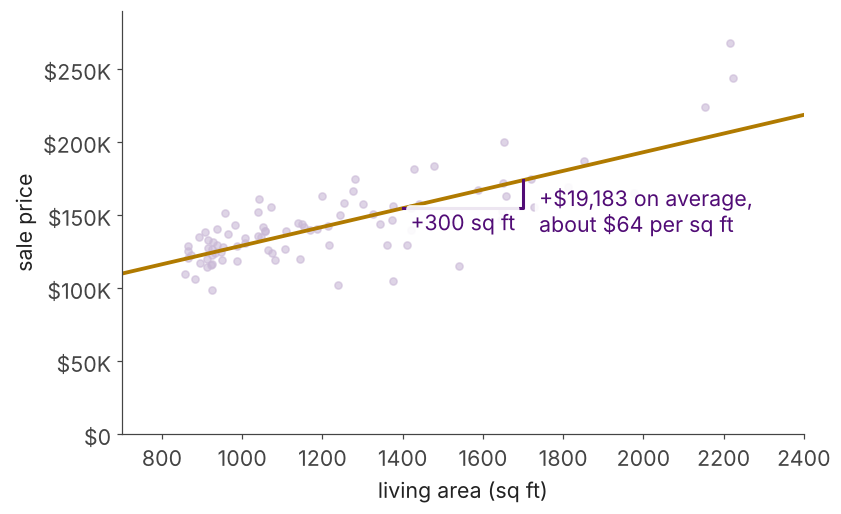

In [ ]:
# @title Show the plotting code
# ---------------- 5/6. reading the line, fit ----------------
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x, y, color=LIGHT, s=22, zorder=2, alpha=0.6)
ax.plot(XS, b0 + b1 * XS, color=GOLD, lw=2.5)
xa, xb = 1400, 1700
ax.plot([xa, xb, xb], [b0 + b1 * xa, b0 + b1 * xa, b0 + b1 * xb], color=PURPLE, lw=2)
WB = dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.9)
ax.text((xa + xb) / 2, b0 + b1 * xa - 15000, "+300 sq ft", ha="center", color=PURPLE, fontsize=14, bbox=WB)
ax.text(xb + 40, b0 + b1 * xa - 2000, f"+${300 * b1:,.0f} on average,\nabout ${b1:,.0f} per sq ft", color=PURPLE, fontsize=14, va="center", bbox=WB)
home_axes(ax)
plt.show()  # f19_slope.png

## Comparing homes is not renovating one

Recall our discussion of experimental design and causality: these are observational data. Larger homes differ from smaller ones in many ways at once, such as age, lot, and quality. The slope describes the association across homes. It does not say what an addition would do to a given home.

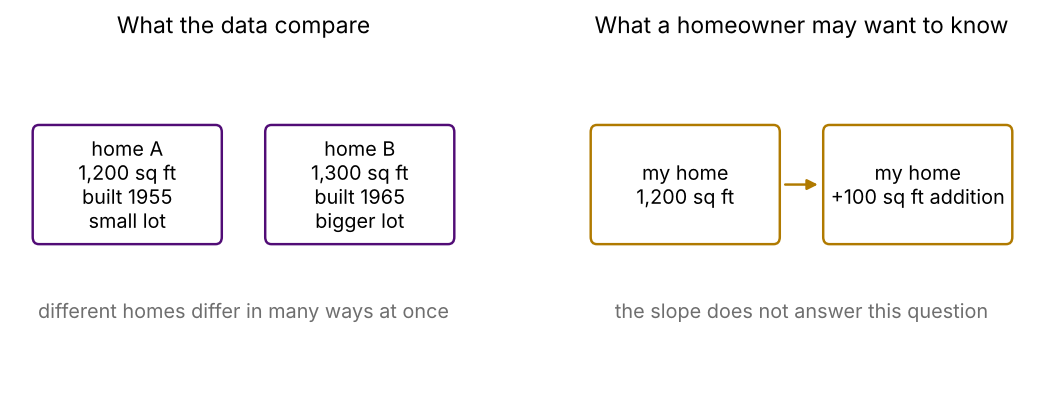

In [ ]:
# @title Show the plotting code
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2));
for ax in axs: ax.set_xlim(0, 6); ax.set_ylim(0, 4); ax.axis("off")
box(axs[0], 1.5, 2.4, 2.4, 1.3, "home A\n1,200 sq ft\nbuilt 1955\nsmall lot")
box(axs[0], 4.5, 2.4, 2.4, 1.3, "home B\n1,300 sq ft\nbuilt 1965\nbigger lot")
axs[0].text(3, 0.9, "different homes differ in many ways at once", ha="center", fontsize=13, color=GRAY)
axs[0].set_title("What the data compare", fontsize=15)
box(axs[1], 1.5, 2.4, 2.4, 1.3, "my home\n1,200 sq ft", ec=GOLD)
box(axs[1], 4.5, 2.4, 2.4, 1.3, "my home\n+100 sq ft addition", ec=GOLD)
arrow(axs[1], (2.75, 2.4), (3.25, 2.4), GOLD)
axs[1].text(3, 0.9, "the slope does not answer this question", ha="center", fontsize=13, color=GRAY)
axs[1].set_title("What a homeowner may want to know", fontsize=15)
plt.show()  # f20_compare_vs_change.png

## The intercept

$b_0 = 65{,}364$ is the value of the line at $x = 0$. No home has 0 square feet, so here $b_0$ only positions the line; do not read it as the value of an empty lot. An intercept can be interpreted only when $x = 0$ is within or near the range of the data.

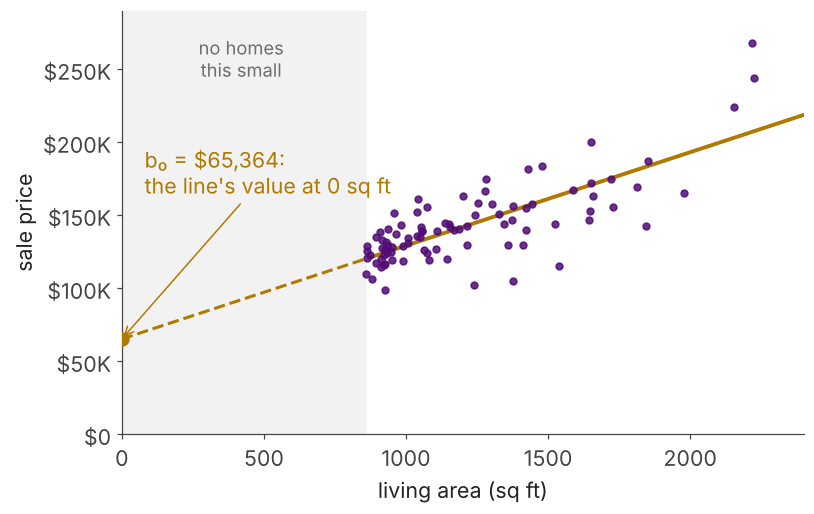

In [ ]:
# @title Show the plotting code
fig, ax = plt.subplots(figsize=(8, 5))
X0 = np.linspace(0, 2400, 100)
ax.axvspan(0, x.min(), color="#F2F2F2")
ax.plot(X0, b0 + b1 * X0, color=GOLD, lw=2, ls="--")
ax.plot(XS[XS >= x.min()], b0 + b1 * XS[XS >= x.min()], color=GOLD, lw=2.5)
ax.scatter(x, y, color=PURPLE, s=20, alpha=0.85, zorder=3)
ax.scatter([0], [b0], color=GOLD, s=70, zorder=4)
ax.annotate(f"b₀ = ${b0:,.0f}:\nthe line's value at 0 sq ft", xy=(0, b0), xytext=(80, 165000),
            arrowprops=dict(arrowstyle="->", color=GOLD), color=GOLD)
ax.text(420, 245000, "no homes\nthis small", ha="center", color=GRAY, fontsize=12)
ax.set_xlim(0, 2400); ax.set_ylim(0, 290000); ax.yaxis.set_major_formatter(DOLLARS)
ax.set_xlabel("living area (sq ft)"); ax.set_ylabel("sale price")
plt.show()  # f21_intercept.png

## Predicted values and residuals

For each home, `model.fittedvalues` is the price the line predicts for its size, and `model.resid` is the residual: the actual price minus the predicted price. A positive residual means the home sold for more than the line predicts; a negative one, for less.

In [ ]:
# @title
homes["predicted"] = model.fittedvalues
homes["residual"] = model.resid
homes[["area", "year_built", "price", "predicted", "residual"]].sort_values("residual").round(0)

,area,year_built,price,predicted,residual
67,1540,1955,115000,163839.0,-48839.0
41,1376,1941,105000,153352.0,-48352.0
79,1238,1950,102000,144528.0,-42528.0
77,1846,1949,143000,183407.0,-40407.0
39,1977,1964,165000,191783.0,-26783.0
...,...,...,...,...,...
43,1280,1966,175000,147214.0,27786.0
34,1652,1959,200000,171001.0,28999.0
30,1042,1965,161000,131995.0,29005.0
2,2223,1973,244000,207514.0,36486.0


Sorting by the residual shows the homes the line misses most. The 2,217 sq ft home at the bottom of the table sold for \$268,000, about \$61,000 more than the line predicts. At the top, a 1,540 sq ft home sold for \$115,000, about \$49,000 less than predicted.

The three largest negative residuals all belong to homes built between 1941 and 1955, older than most homes in the data (half were built after 1959). The line knows only size; age is one of the things in $\varepsilon$. Adding explanatory variables like this one is what multiple regression does.

## Predicting, and extrapolating

For a 1,500 sq ft home, $\hat{y} = 65{,}364 + 63.94(1{,}500) \approx \$161{,}000$. For a 3,800 sq ft home the line gives about \$308,000, but no home in the data is larger than 2,223 square feet, and we have no idea whether the straight line still holds out there.

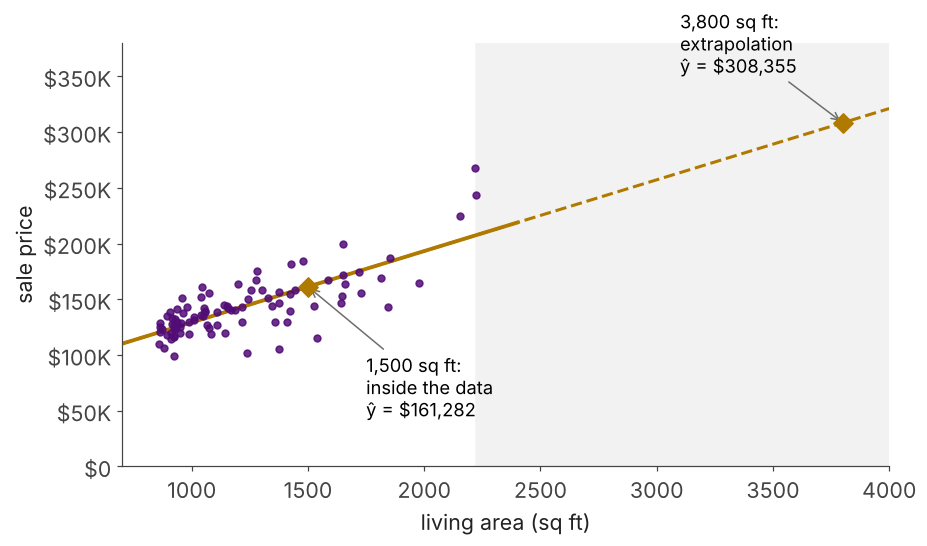

In [ ]:
# @title Show the plotting code
fig, ax = plt.subplots(figsize=(9, 5))
XE = np.linspace(700, 4000, 100)
ax.axvspan(x.max(), 4000, color="#F2F2F2")
ax.plot(XE, b0 + b1 * XE, color=GOLD, lw=2, ls="--"); ax.plot(XS, b0 + b1 * XS, color=GOLD, lw=2.5)
ax.scatter(x, y, color=PURPLE, s=20, alpha=0.85, zorder=3)
for xp, lab in [(1500, "1,500 sq ft:\ninside the data"), (3800, "3,800 sq ft:\nextrapolation")]:
    yp = b0 + b1 * xp
    ax.scatter([xp], [yp], color=GOLD, s=80, zorder=4, marker="D")
    ax.annotate(f"{lab}\nŷ = ${yp:,.0f}", xy=(xp, yp), xytext=(xp - 700 if xp > 3000 else xp + 250, yp + 45000 if xp > 3000 else 45000),
                arrowprops=dict(arrowstyle="->", color=GRAY), fontsize=12)
ax.set_xlim(700, 4000); ax.set_ylim(0, 380000); ax.yaxis.set_major_formatter(DOLLARS)
ax.set_xlabel("living area (sq ft)"); ax.set_ylabel("sale price")
plt.show()  # f22_prediction.png

In [ ]:
# @title
model.predict(pd.DataFrame({"area": [1500, 3800]}))

0    161281.564070
1    308354.935481
dtype: float64

## Splitting each home's price

Without $x$, our best guess for every home is the average price $\bar{y}$. For each home, the distance from $\bar{y}$ splits into the part the line explains and the residual:

$$(y_i - \bar{y}) = (\hat{y}_i - \bar{y}) + (y_i - \hat{y}_i)$$

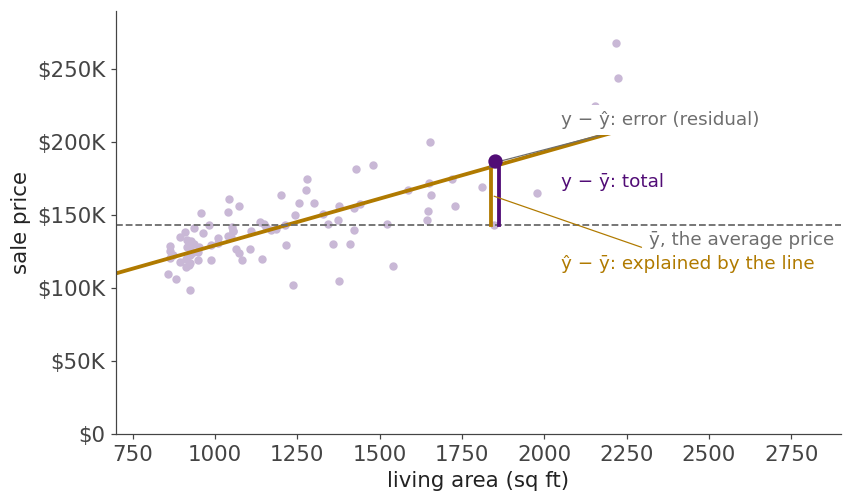

In [8]:
# @title Show the plotting code
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.scatter(x, y, color=LIGHT, s=20, zorder=2)
ax.plot(XS, b0 + b1 * XS, color=GOLD, lw=2.5); ax.axhline(ybar, color=GRAY, ls="--", lw=1.2)
j = int(np.argmax(np.where((x > 1700) & (x < 2000), y - yhat, -1e9)))
xj, yj, yhj = x[j], y[j], yhat[j]
ax.scatter([xj], [yj], color=PURPLE, s=70, zorder=4)
ax.plot([xj + 12] * 2, [ybar, yj], color=PURPLE, lw=2.5)
ax.plot([xj - 12] * 2, [ybar, yhj], color=GOLD, lw=2.5)
ax.plot([xj - 12] * 2, [yhj, yj], color=GRAY, lw=2.5)
ax.annotate("y − ŷ: error (residual)", xy=(xj - 12, (yj + yhj) / 2), xytext=(xj + 200, yj + 25000), color=GRAY, bbox=dict(fc="white", ec="none"),
            fontsize=12, arrowprops=dict(arrowstyle="-", color=GRAY, lw=0.8))
ax.text(xj + 200, (yj + ybar) / 2 + 4000, "y − ȳ: total", color=PURPLE, fontsize=12, bbox=dict(fc="white", ec="none"))
ax.annotate("ŷ − ȳ: explained by the line", xy=(xj - 12, (yhj + ybar) / 2), xytext=(xj + 200, ybar - 30000), color=GOLD, bbox=dict(fc="white", ec="none"),
            fontsize=12, arrowprops=dict(arrowstyle="-", color=GOLD, lw=0.8))
ax.text(2880, ybar - 14000, "ȳ, the average price", color=GRAY, fontsize=12, ha="right")
home_axes(ax, xlim=(700, 2900))
plt.show()  # f23_decomposition.png

## Sums of squares

Square each part and add over all homes, and the pieces still add up:

| | Formula | North Ames |
|---|---|---:|
| Total, SST | $\sum (y - \bar{y})^2$ | 68.55 billion |
| Explained by the line, SSR | $\sum (\hat{y} - \bar{y})^2$ | 40.54 billion |
| Error, SSE | $\sum (y - \hat{y})^2$ | 28.00 billion |

$$SST = SSR + SSE$$

This is the same structure as the ANOVA table, where total = between + within. SSE is the quantity least squares made as small as possible.

Software labels differ, so watch out. Excel's ANOVA table calls the rows Regression and Residual. In statsmodels, `model.ssr` is the sum of squared **residuals**, which is our SSE, and `model.ess` is the explained sum of squares, our SSR.

In [ ]:
# @title
sst = model.centered_tss
ssr = model.ess        # explained by the line: our SSR
sse = model.ssr        # sum of squared residuals: our SSE
print(f"SST = {sst:,.0f}\nSSR = {ssr:,.0f}\nSSE = {sse:,.0f}")

SST = 68,547,065,618
SSR = 40,543,330,867
SSE = 28,003,734,751


## R², the coefficient of determination

This is the `R-squared` in the summary.

$$R^2 = \frac{SSR}{SST} = 1 - \frac{SSE}{SST} = \frac{40.54}{68.55} = 0.59$$

*Living area explains about 59% of the variation in sale prices among these 89 homes.*

R² does not mean that the line predicts 59% of homes correctly, and it does not mean that 59% of the price is caused by size.

In [ ]:
# @title
model.rsquared

np.float64(0.5914670526240888)

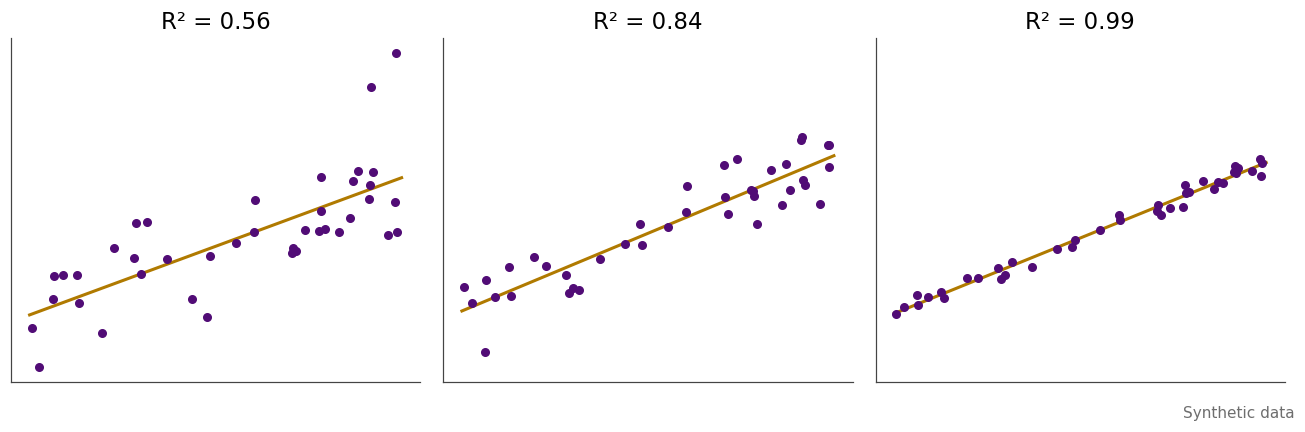

In [5]:
# @title Show the plotting code
import scipy.stats as stats
rng9 = np.random.default_rng(9)
xx = rng9.uniform(0, 10, 40)
fig, axs = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, sd in zip(axs, [6, 2.5, 0.8]):
    yy = 5 + 2 * xx + rng9.normal(0, sd, 40)
    aa, bb = fit(xx, yy)
    ax.scatter(xx, yy, color=PURPLE, s=24, zorder=3); ax.plot([0, 10], [aa, aa + 10 * bb], color=GOLD, lw=2)
    ax.set_title(f"R² = {stats.pearsonr(xx, yy)[0] ** 2:.2f}", fontsize=15); ax.set_xticks([]); ax.set_yticks([])
fig.text(0.99, -0.03, "Synthetic data", ha="right", fontsize=10, color=GRAY)
fig.tight_layout(); plt.show()  # f24_r2_compare.png

Same line, different scatter. The closer the points lie to the line, the larger R². It is always between 0 and 1.

## The typical prediction error, $s_e$

$$s_e = \sqrt{\frac{SSE}{n-2}} = \sqrt{MSE} = \$17{,}941$$

$s_e$ estimates $\sigma_\varepsilon$, the standard deviation of the error $\varepsilon$. We divide by $n - 2$, the `Df Residuals` in the summary, because two numbers, $b_0$ and $b_1$, were estimated from the data. In plain words, a typical home sells about \$18,000 above or below the line.

The summary does not print $s_e$ directly; `model.mse_resid` gives $SSE/(n-2)$, and its square root is $s_e$. Our textbook and Excel write it simply as $s$ (Excel's label is Standard Error, in the Regression Statistics table). We add the subscript $e$ to keep it apart from $s_y$, the ordinary standard deviation of the prices.

In [ ]:
# @title
np.sqrt(model.mse_resid)

np.float64(17941.070442725304)

<>:7: SyntaxWarning: invalid escape sequence '\$'
<>:7: SyntaxWarning: invalid escape sequence '\$'
/tmp/ipykernel_2664/3989049135.py:7: SyntaxWarning: invalid escape sequence '\$'
  ax.text(s_e + 2000, ax.get_ylim()[1] * 0.85, f"$+s_e$ = \${s_e:,.0f}", color=GOLD, fontsize=13)


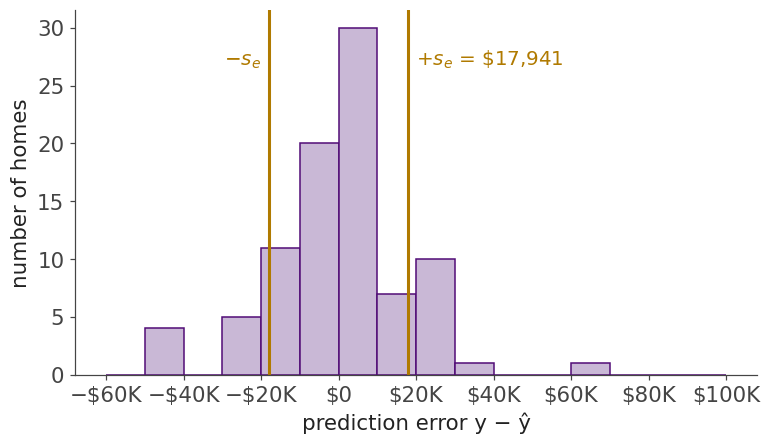

In [6]:
# @title Show the plotting code
s_e = np.sqrt(model.mse_resid)
fig, ax = plt.subplots(figsize=(8, 4.3))
ax.hist(res, bins=np.arange(-60000, 100001, 10000), color=LIGHT, edgecolor=PURPLE)
for v in (-s_e, s_e):
    ax.axvline(v, color=GOLD, lw=2)
ax.text(s_e + 2000, ax.get_ylim()[1] * 0.85, f"$+s_e$ = \${s_e:,.0f}", color=GOLD, fontsize=13)
ax.text(-s_e - 2000, ax.get_ylim()[1] * 0.85, "$-s_e$", color=GOLD, fontsize=13, ha="right")
ax.xaxis.set_major_formatter(DOLLARS); ax.set_xlabel("prediction error y − ŷ"); ax.set_ylabel("number of homes")
plt.show()  # f25_residual_hist.png

## Two different spreads

Since $y = \beta_0 + \beta_1 x + \varepsilon$, homes of a given size vary around the line only through $\varepsilon$. So $\sigma_\varepsilon$ is also the standard deviation of $Y$ given $X = x$: the spread of prices among homes of the same size. The equal-variance assumption is what lets one number describe that spread at every size.

It is not the spread of all prices. That one, $s_y$, also includes the differences that come from homes being different sizes.

| | Population | Sample | North Ames |
|---|---|---|---|
| Spread of all prices | $\sigma_Y$ | $s_y$ | \$27,910 |
| Spread around the line: of $Y$ given $X = x$, and of $\varepsilon$ | $\sigma_\varepsilon$ | $s_e$ | \$17,941 |

<>:12: SyntaxWarning: invalid escape sequence '\$'
<>:26: SyntaxWarning: invalid escape sequence '\$'
<>:12: SyntaxWarning: invalid escape sequence '\$'
<>:26: SyntaxWarning: invalid escape sequence '\$'
/tmp/ipykernel_2664/3274786288.py:12: SyntaxWarning: invalid escape sequence '\$'
  axs[0].set_title(f"All prices: $s_y$ = \${s_y:,.0f}")
/tmp/ipykernel_2664/3274786288.py:26: SyntaxWarning: invalid escape sequence '\$'
  axs[1].set_title(f"Around the line, at any given size: $s_e$ = \${s_e:,.0f}")


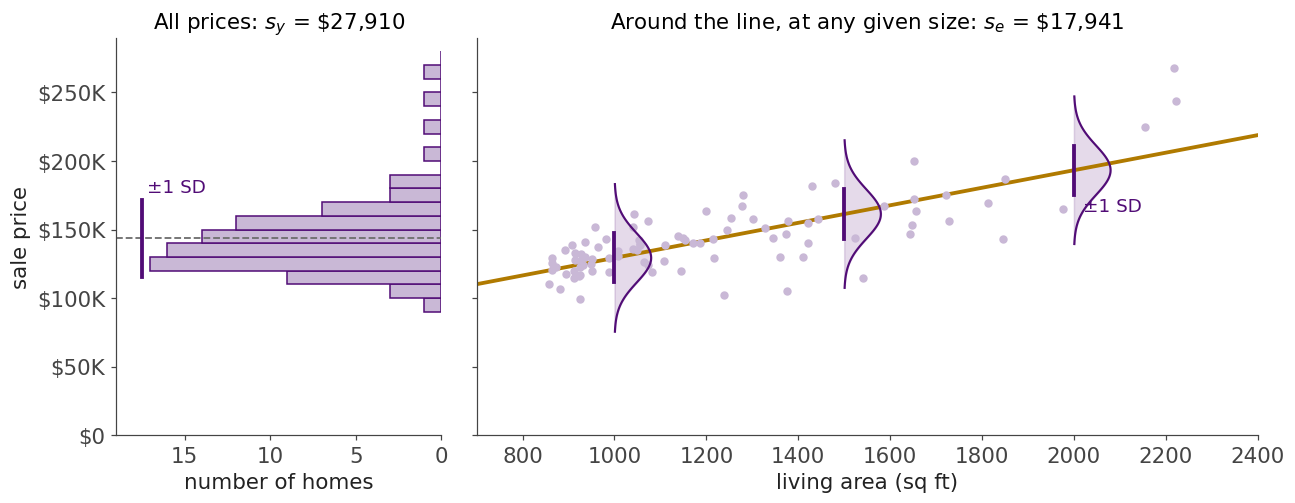

In [7]:
# @title Show the plotting code
# ---------------- 6. spread of prices overall vs around the line ----------------
import scipy.stats as stats
s_y = y.std(ddof=1)
s_e = np.sqrt(model.mse_resid)
ybar = y.mean()
fig, axs = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True, gridspec_kw={"width_ratios": [1, 2.4]})
axs[0].hist(y, bins=np.arange(90000, 280001, 10000), orientation="horizontal", color=LIGHT, edgecolor=PURPLE)
axs[0].axhline(ybar, color=GRAY, ls="--", lw=1.2)
axs[0].plot([17.5, 17.5], [ybar - s_y, ybar + s_y], color=PURPLE, lw=2.5)
axs[0].set_xlim(19, 0); axs[0].set_xlabel("number of homes")
axs[0].set_title(f"All prices: $s_y$ = \${s_y:,.0f}")
axs[0].yaxis.set_major_formatter(DOLLARS); axs[0].set_ylim(0, 290000); axs[0].set_ylabel("sale price")
axs[1].plot(XS, b0 + b1 * XS, color=GOLD, lw=2.5)
axs[1].scatter(x, y, color=LIGHT, s=20, zorder=2)
for xc in [1000, 1500, 2000]:
    mu = b0 + b1 * xc
    yy = np.linspace(mu - 3 * s_e, mu + 3 * s_e, 100)
    dd = stats.norm.pdf(yy, mu, s_e) * s_e * 200
    axs[1].fill_betweenx(yy, xc, xc + dd, color=PURPLE, alpha=0.15)
    axs[1].plot(xc + dd, yy, color=PURPLE, lw=1.4)
    axs[1].plot([xc, xc], [mu - s_e, mu + s_e], color=PURPLE, lw=2.5)
axs[0].text(17.2, ybar + s_y + 6000, "±1 SD", color=PURPLE, fontsize=12)
axs[1].text(2020, b0 + b1 * 2000 - s_e - 12000, "±1 SD", color=PURPLE, fontsize=12, ha="left")
home_axes(axs[1]); axs[1].set_ylabel("")
axs[1].set_title(f"Around the line, at any given size: $s_e$ = \${s_e:,.0f}")
fig.tight_layout(); plt.show()  # f36_two_spreads.png

In [ ]:
# @title
s_y = homes["price"].std()
s_e = np.sqrt(model.mse_resid)
print(f"s_y = {s_y:,.0f}   s_e = {s_e:,.0f}")

s_y = 27,910   s_e = 17,941


Knowing a home's size shrinks the typical miss from about \$28,000 to about \$18,000.

## Reading the diagnostic plots

The same four plots as in the previous notebook. Each one checks an assumption about $\varepsilon$ from our list, using the residuals as stand-ins for the errors.

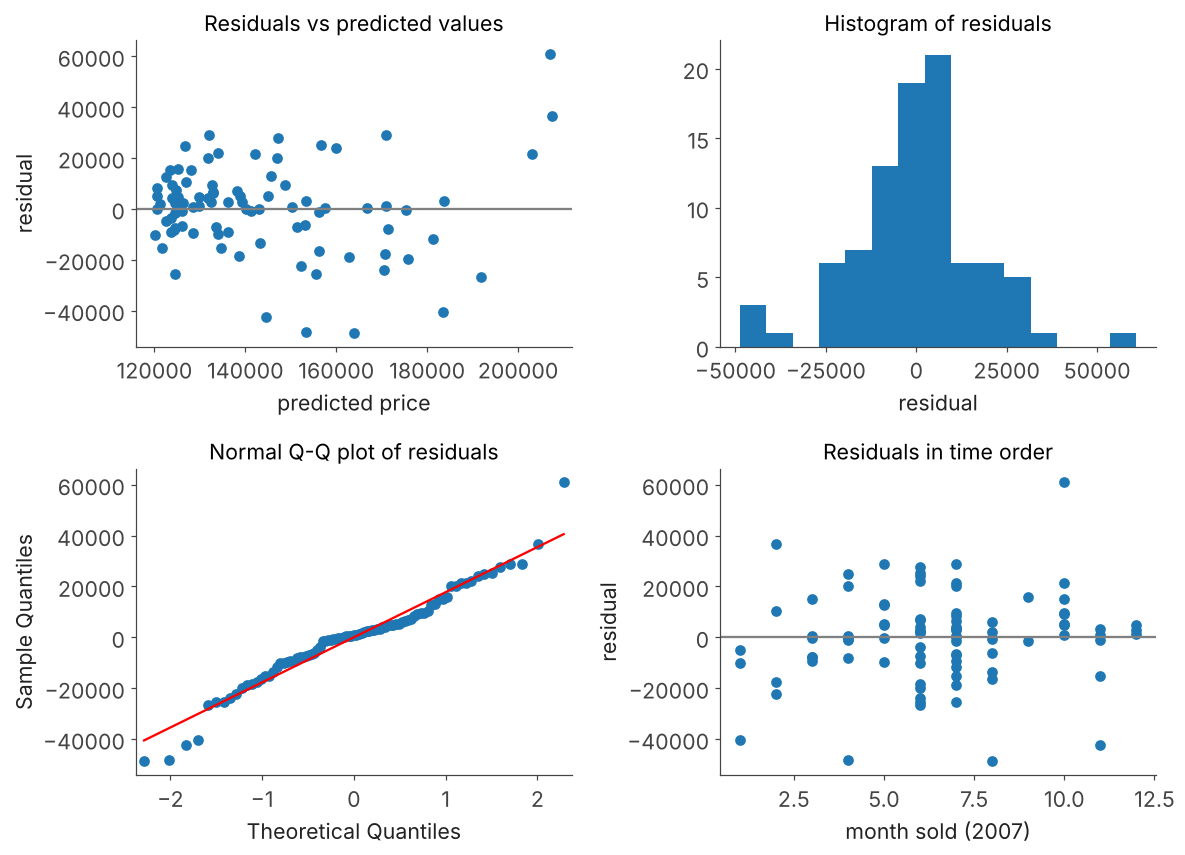

In [ ]:
# @title
fig, axs = plt.subplots(2, 2, figsize=(11, 8))

axs[0, 0].scatter(model.fittedvalues, model.resid)
axs[0, 0].axhline(0, color="gray")
axs[0, 0].set_xlabel("predicted price")
axs[0, 0].set_ylabel("residual")
axs[0, 0].set_title("Residuals vs predicted values")

axs[0, 1].hist(model.resid, bins=15)
axs[0, 1].set_xlabel("residual")
axs[0, 1].set_title("Histogram of residuals")

sm.qqplot(model.resid, line="s", ax=axs[1, 0])
axs[1, 0].set_title("Normal Q-Q plot of residuals")

axs[1, 1].scatter(homes["month_sold"], model.resid)
axs[1, 1].axhline(0, color="gray")
axs[1, 1].set_xlabel("month sold (2007)")
axs[1, 1].set_ylabel("residual")
axs[1, 1].set_title("Residuals in time order")

plt.tight_layout()
plt.show()

- **Residuals vs predicted values (linearity, equal variance):** mostly a patternless band around zero. The two largest homes, on the far right, both sold well above the line, a hint that prices rise faster than a straight line for the biggest homes. There is no clear funnel.
- **Histogram and Q-Q plot (normality):** the residuals are roughly symmetric and the Q-Q points follow the line in the middle. At both ends they bend away from it: a few homes sold for much less, and one for much more, than a normal distribution would suggest.
- **Residuals in time order (independence):** no pattern across the months of 2007. Sales cluster in June and July, which only changes how many dots each month has.

None of this is alarming for 89 homes, but the two large homes and the old homes with big negative residuals are worth remembering when we add more variables.